# Exploring weekly dengue reports in Sri Lanka

My first task is to identify the available dates, district names and case
counts before choosing the study period.

Data source: denguedatahub, srilanka_weekly_data.
Original source: Weekly Epidemiological Reports, Ministry of Health, Sri Lanka.
AI assistance: ChatGPT helped draft the initial data-loading snippet.

In [1]:
import pandas as pd

data_url = (
    "https://thiyangt.r-universe.dev/denguedatahub/"
    "data/srilanka_weekly_data/csv"
)

dengue = pd.read_csv(data_url)

print("Rows and columns:", dengue.shape)
print("Column names:", dengue.columns.tolist())
display(dengue.head())

Rows and columns: (26753, 6)
Column names: ['year', 'week', 'start.date', 'end.date', 'district', 'cases']


,year,week,start.date,end.date,district,cases
0,2006,52,12/23/2006,12/29/2006,Colombo,71
1,2006,52,12/23/2006,12/29/2006,Gampaha,12
2,2006,52,12/23/2006,12/29/2006,Kalutara,12
3,2006,52,12/23/2006,12/29/2006,Kandy,20
4,2006,52,12/23/2006,12/29/2006,Matale,4


In [3]:
import pandas as pd

weekly = dengue.copy()
weekly["district"] = weekly["district"].str.strip()

def parse_report_date(column):
    slash_dates = pd.to_datetime(column, format="%m/%d/%Y", errors="coerce")
    iso_dates = pd.to_datetime(column, format="%Y-%m-%d", errors="coerce")
    return slash_dates.fillna(iso_dates)

weekly["week_start"] = parse_report_date(weekly["start.date"])
weekly["week_end"] = parse_report_date(weekly["end.date"])

print("Unreadable start dates:", weekly["week_start"].isna().sum())
print("Unreadable end dates:", weekly["week_end"].isna().sum())
print("First reporting week starts:", weekly["week_start"].min().date())
print("Last reporting week starts:", weekly["week_start"].max().date())
print("Last reporting week ends:", weekly["week_end"].max().date())

Unreadable start dates: 0
Unreadable end dates: 0
First reporting week starts: 2006-12-23
Last reporting week starts: 2026-09-07
Last reporting week ends: 2026-09-13


In [4]:
# One row per reporting week, one column per original reporting area.
area_cases = weekly.pivot(
    index="week_start",
    columns="district",
    values="cases"
).sort_index()

# Combine the two Ampara reporting areas into one administrative district.
district_cases = area_cases.copy()
district_cases["Ampara"] = area_cases["Ampara"] + area_cases["Kalmune"]
district_cases = district_cases.drop(columns="Kalmune")

# Standardise two labels for display in the dashboard.
district_cases = district_cases.rename(columns={
    "Hambanthota": "Hambantota",
    "NuwaraEliya": "Nuwara Eliya"
}).sort_index(axis="columns")

print("Original reporting areas:", area_cases.shape[1])
print("Reporting weeks and districts:", district_cases.shape)
display(district_cases.head())

Original reporting areas: 26
Reporting weeks and districts: (1029, 25)


district,Ampara,Anuradhapura,Badulla,Batticaloa,Colombo,Galle,Gampaha,Hambantota,Jaffna,Kalutara,...,Matale,Matara,Monaragala,Mullaitivu,Nuwara Eliya,Polonnaruwa,Puttalam,Ratnapura,Trincomalee,Vavuniya
week_start,,,,,,,,,,,,,,,,,,,,,
2006-12-23,0.0,4.0,2.0,0.0,71.0,1.0,12.0,1.0,0.0,12.0,...,4.0,11.0,0.0,0.0,1.0,1.0,6.0,1.0,0.0,3.0
2006-12-30,0.0,0.0,0.0,0.0,40.0,10.0,11.0,1.0,0.0,20.0,...,2.0,8.0,0.0,0.0,4.0,4.0,13.0,5.0,2.0,3.0
2007-01-06,0.0,0.0,2.0,0.0,43.0,4.0,13.0,2.0,0.0,7.0,...,7.0,8.0,1.0,0.0,2.0,0.0,9.0,3.0,1.0,0.0
2007-01-13,0.0,0.0,2.0,0.0,38.0,4.0,16.0,1.0,0.0,6.0,...,7.0,4.0,1.0,0.0,2.0,2.0,11.0,2.0,2.0,0.0
2007-01-20,0.0,2.0,1.0,0.0,52.0,3.0,12.0,1.0,0.0,15.0,...,4.0,4.0,3.0,0.0,3.0,2.0,8.0,2.0,2.0,2.0


In [5]:
missing_records = (
    district_cases.isna()
    .rename_axis(index="week_start", columns="district")
    .stack()
)

print("Missing district-week records:", missing_records.sum())
print(missing_records[missing_records].index.tolist())

Missing district-week records: 1
[(Timestamp('2026-02-09 00:00:00'), 'Puttalam')]


#Baseline forecast and evaluation

In [6]:
district_cases = district_cases.sort_index()
weeks = district_cases.index

train_weeks = weeks[:-104]        # Earlier weeks for training future models
validation_weeks = weeks[-104:-52]  # Next 52 weeks for comparing approaches
test_weeks = weeks[-52:]          # Final 52 weeks for the final evaluation

for name, dates in [
    ("Training", train_weeks),
    ("Validation", validation_weeks),
    ("Test", test_weeks),
]:
    print(f"{name}: {len(dates)} weeks | {dates.min().date()} to {dates.max().date()}")

Training: 925 weeks | 2006-12-23 to 2024-09-07
Validation: 52 weeks | 2024-09-14 to 2025-09-06
Test: 52 weeks | 2025-09-13 to 2026-09-07


In [7]:
# Move each district's observed count forward by exactly seven days.
# Keep only the target weeks we want to evaluate.
validation_pred = district_cases.shift(freq="7D").reindex(validation_weeks)
validation_actual = district_cases.loc[validation_weeks]

# Inspect one district so we can check the calculation by hand.
colombo_example = pd.DataFrame({
    "predicted_cases": validation_pred["Colombo"],
    "actual_cases": validation_actual["Colombo"],
})

colombo_example["absolute_error"] = (
    colombo_example["actual_cases"] - colombo_example["predicted_cases"]
).abs()

display(colombo_example.head())

,predicted_cases,actual_cases,absolute_error
week_start,,,
2024-09-14,226.0,202.0,24.0
2024-09-21,202.0,143.0,59.0
2024-09-28,143.0,169.0,26.0
2024-10-05,169.0,172.0,3.0
2024-10-12,172.0,180.0,8.0


In [8]:
absolute_errors = (validation_actual - validation_pred).abs()

# One error for each district-week with both a prediction and an actual count.
scored_errors = absolute_errors.stack()
baseline_mae = scored_errors.mean()

print("District-week predictions scored:", len(scored_errors))
print(f"Baseline validation MAE: {baseline_mae:.2f} cases")

district_results = pd.DataFrame({
    "weeks_scored": absolute_errors.count(),
    "mae_cases": absolute_errors.mean(),
})

display(district_results.sort_values("mae_cases", ascending=False).round(2))

District-week predictions scored: 1300
Baseline validation MAE: 9.00 cases


,weeks_scored,mae_cases
district,,
Colombo,52,31.56
Gampaha,52,21.85
Ratnapura,52,19.40
Kandy,52,16.85
Kalutara,52,12.71
Galle,52,12.25
Matara,52,11.15
Kegalle,52,9.50
Kurunegala,52,9.02


The baseline produced 1,300 validation predictions: 52 weeks for each of
the 25 districts. Across those predictions, the forecast differed from the
reported count by an average of 9.00 cases per district-week.

Colombo's average error was 31.56 cases, which is larger than the overall
average. This tells me the size of the error varies by district.

## Random Forest forecast for all 25 districts

Goal is to predict the weekly reported dengue count for each district.
The baseline uses only the previous week's count. For the Random Forest,
I will also provide the counts from two, three and four weeks earlier,
along with the district and calendar month.

Each row represents one district in one target week. A feature is an input
the model can use to make a prediction. The target is the actual case count
that I want it to predict.

In [9]:
# Use only the history needed for training and validation.
history = district_cases.loc[:validation_weeks[-1]]

# stack() turns the wide table into values indexed by week and district.
columns = {"actual_cases": history.stack()}

for lag in (1, 2, 3, 4):
    earlier_counts = history.shift(freq=pd.Timedelta(weeks=lag))
    earlier_counts = earlier_counts.reindex(history.index)
    columns[f"lag_{lag}"] = earlier_counts.stack()

# Keep rows with a known target and all four historical counts.
model_data = pd.DataFrame(columns).dropna().reset_index()
model_data["month"] = model_data["week_start"].dt.month

features = ["district", "month", "lag_1", "lag_2", "lag_3", "lag_4"]

train = model_data.loc[model_data["week_start"].isin(train_weeks)].copy()
valid = model_data.loc[model_data["week_start"].isin(validation_weeks)].copy()

print("Training rows:", len(train))
print("Validation rows:", len(valid))

# Check one familiar example before fitting the model.
display(
    valid.loc[
        valid["district"] == "Colombo",
        ["week_start", "lag_1", "lag_2", "lag_3", "lag_4", "actual_cases"]
    ].head(1)
)

Training rows: 22825
Validation rows: 1300


,week_start,lag_1,lag_2,lag_3,lag_4,actual_cases
22829,2024-09-14,226.0,192.0,250.0,263.0,202.0


### Train one Random Forest across all districts

A Random Forest trains several decision trees and averages their numeric
predictions. I train one forest using historical examples from all 25
districts. This lets it learn from shared patterns while still using the
district name as an input.

I encode district names as separate indicator columns. This gives the model
a way to recognise each district without assigning an artificial ranking
to names such as Colombo, Kandy and Galle.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

preprocess = ColumnTransformer(
    transformers=[
        ("district", OneHotEncoder(handle_unknown="ignore"), ["district"])
    ],
    remainder="passthrough"  # Keep the month and four case-count columns.
)

rf_model = make_pipeline(
    preprocess,
    RandomForestRegressor(
        n_estimators=100,    # Train 100 trees.
        max_depth=12,        # Limit how many levels each tree can grow.
        min_samples_leaf=5,  # Require at least 5 training rows per final leaf.
        random_state=42,     # Make repeat runs reproducible.
        n_jobs=-1
    )
)

rf_model.fit(train[features], train["actual_cases"])
print("Random Forest training complete.")

Random Forest training complete.


### Compare Random Forest with the baseline

I evaluate both methods on exactly the same district-week records.
For each row, the baseline prediction is lag_1, which is the reported
count from one week earlier. The Random Forest makes its prediction using
all six features.

I compare their mean absolute errors in units of reported cases. A lower
MAE means the model's predictions were closer to the observed counts on
average during validation.

In [11]:
rf_results = valid[["week_start", "district", "actual_cases", "lag_1"]].copy()
rf_results = rf_results.rename(columns={"lag_1": "baseline_prediction"})
rf_results["rf_prediction"] = rf_model.predict(valid[features])

rf_results["baseline_error"] = (
    rf_results["actual_cases"] - rf_results["baseline_prediction"]
).abs()

rf_results["rf_error"] = (
    rf_results["actual_cases"] - rf_results["rf_prediction"]
).abs()

baseline_mae = rf_results["baseline_error"].mean()
rf_mae = rf_results["rf_error"].mean()

print(f"District-week records compared: {len(rf_results)}")
print(f"Baseline MAE:      {baseline_mae:.2f} cases")
print(f"Random Forest MAE: {rf_mae:.2f} cases")
print(f"Reduction in MAE:  {baseline_mae - rf_mae:.2f} cases")

# A positive reduction means Random Forest did better in that district.
district_comparison = (
    rf_results.groupby("district")[["baseline_error", "rf_error"]]
    .mean()
    .rename(columns={"baseline_error": "baseline_mae", "rf_error": "rf_mae"})
)
district_comparison["mae_reduction"] = (
    district_comparison["baseline_mae"] - district_comparison["rf_mae"]
)

display(district_comparison.sort_values("mae_reduction", ascending=False).round(2))

District-week records compared: 1300
Baseline MAE:      9.00 cases
Random Forest MAE: 8.49 cases
Reduction in MAE:  0.51 cases


,baseline_mae,rf_mae,mae_reduction
district,,,
Kandy,16.85,13.48,3.37
Galle,12.25,9.50,2.75
Ratnapura,19.40,17.76,1.64
Kalutara,12.71,11.28,1.43
Kegalle,9.50,8.07,1.43
Matara,11.15,9.76,1.39
Matale,8.62,7.29,1.32
Kurunegala,9.02,8.18,0.84
Puttalam,5.87,5.21,0.65


### Interpretation

Across 1,300 district-week validation records, the baseline had an MAE of
9.00 reported cases and the Random Forest had an MAE of 8.49. The forest
reduced the average absolute error by about 0.51 cases per prediction.

The combined use of earlier counts, month and district produced a modest
overall improvement during this validation period. This comparison alone
does not tell me which individual feature caused the improvement.

The largest reduction in MAE was in ______, where the baseline MAE was
______ and the Random Forest MAE was ______.

### Random Forest validation results

I compared Random Forest with the previous-week baseline on 1,300 forecasts
covering 25 districts. The mean absolute error decreased from 9.00 to 8.49
reported cases per district-week.

Random Forest improved on the baseline in 22 of the 25 districts. Kandy had
the largest improvement: its MAE fell from 16.85 to 13.48 cases. Colombo
showed the opposite pattern: its MAE increased from 31.56 to 35.95 cases.

These results show why the dashboard should display district-level errors
alongside the overall score. The scores identify where the model struggled;
understanding why requires inspecting the weekly predictions.

## XGBoost forecast for all 25 districts

Random Forest averages predictions from many trees. XGBoost builds trees
in sequence, with each new tree helping to correct errors in the combined
prediction so far. This approach is called boosting.

To make the comparison fair, I use the same 22,825 training rows, six input
features and 1,300 validation rows as the Random Forest experiment. The
final test period stays reserved for the end of the project.

In [12]:
import xgboost
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.pipeline import make_pipeline

print("XGBoost version:", xgboost.__version__)

# Reuse the same district encoding and numeric features as Random Forest.
# A dense table keeps zero case counts explicitly represented as zeros.
xgb_preprocess = clone(preprocess).set_params(sparse_threshold=0.0)

xgb_model = make_pipeline(
    xgb_preprocess,
    XGBRegressor(
        objective="reg:squarederror",
        n_estimators=200,     # Build 200 trees in sequence.
        learning_rate=0.05,   # Each tree makes a small adjustment.
        max_depth=3,          # Keep each individual tree shallow.
        tree_method="hist",
        random_state=42,
        n_jobs=2
    )
)

xgb_model.fit(train[features], train["actual_cases"])
print("XGBoost training complete.")

XGBoost version: 3.4.1
XGBoost training complete.


### Compare the three forecasting methods

For every district-week, I now have one actual case count and three
predictions: the previous-week baseline, Random Forest and XGBoost.

I calculate the absolute error for each prediction and average those errors
over the same validation records. I also compare errors within each district
to see whether the overall ranking holds locally.

In [13]:
# rf_results already contains the actual counts and the first two predictions.
comparison = rf_results.copy()
comparison["xgb_prediction"] = pd.Series(
    xgb_model.predict(valid[features]),
    index=valid.index
)

predictions = comparison[
    ["baseline_prediction", "rf_prediction", "xgb_prediction"]
].copy()
predictions.columns = ["Baseline", "Random Forest", "XGBoost"]

# Check that every method is scored on every validation record.
assert predictions.notna().all().all(), "Some validation predictions are missing."

errors = predictions.sub(comparison["actual_cases"], axis="index").abs()

overall_mae = errors.mean().sort_values().rename("Validation MAE")
print("District-week records compared:", len(errors))
display(overall_mae.round(2).to_frame())

district_mae = errors.groupby(comparison["district"]).mean()
district_mae["RF MAE minus XGBoost MAE"] = (
    district_mae["Random Forest"] - district_mae["XGBoost"]
)

xgb_wins = (district_mae["RF MAE minus XGBoost MAE"] > 0).sum()
print(f"XGBoost had lower MAE than Random Forest in {xgb_wins} districts.")

display(
    district_mae.sort_values("RF MAE minus XGBoost MAE", ascending=False)
    .round(2)
)

District-week records compared: 1300


,Validation MAE
XGBoost,8.14
Random Forest,8.49
Baseline,9.00


XGBoost had lower MAE than Random Forest in 16 districts.


,Baseline,Random Forest,XGBoost,RF MAE minus XGBoost MAE
district,,,,
Colombo,31.56,35.95,31.45,4.50
Gampaha,21.85,21.68,19.12,2.56
Kalutara,12.71,11.28,10.24,1.04
Matale,8.62,7.29,6.63,0.66
Trincomalee,4.40,5.18,4.66,0.52
Ampara,6.37,5.87,5.57,0.30
Matara,11.15,9.76,9.48,0.28
Hambantota,5.83,5.65,5.44,0.20
Ratnapura,19.40,17.76,17.56,0.20


### XGBoost validation results

Across 1,300 district-week forecasts, XGBoost achieved a mean absolute
error of 8.14 cases, compared with 8.49 for Random Forest and 9.00 for
the previous-week baseline. XGBoost had lower error than Random Forest
in 16 of the 25 districts.

Colombo had the largest improvement over Random Forest. Its MAE fell
from 35.95 to 31.45 cases. However, the simple baseline achieved 31.56
there, so XGBoost's advantage over the baseline was small. In Kandy,
Random Forest remained the best of the three methods.

## Visual comparison of the forecasting models

### Overall validation error

This graph compares the mean absolute error (MAE) of the baseline, Random
Forest and XGBoost across the same 1,300 district-week forecasts. A shorter
bar means the predictions were closer to the reported counts on average.
The horizontal axis is measured in reported cases per district-week.

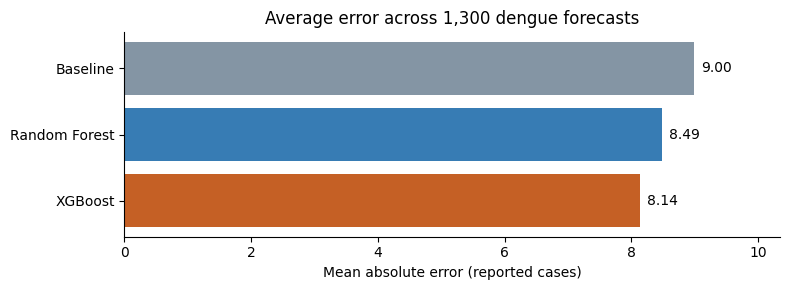

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

model_colors = {
    "Baseline": "#8495a4",
    "Random Forest": "#377cb4",
    "XGBoost": "#c56025",
}

scores = overall_mae.reindex(["Baseline", "Random Forest", "XGBoost"])

fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(scores.index, scores, color=[model_colors[m] for m in scores.index])

ax.bar_label(bars, fmt="%.2f", padding=5)
ax.invert_yaxis()
ax.set_xlim(0, scores.max() * 1.15)
ax.set_xlabel("Mean absolute error (reported cases)")
ax.set_title("Average error across 1,300 dengue forecasts")
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

### Weekly reported cases and model predictions

I compare the actual and predicted counts week by week for one district.
The dark line shows reported cases. The other lines show the forecasts
made using information from earlier weeks.

I start with Colombo because the baseline had the lowest MAE there.
This graph lets me investigate why a simple forecast remained competitive.

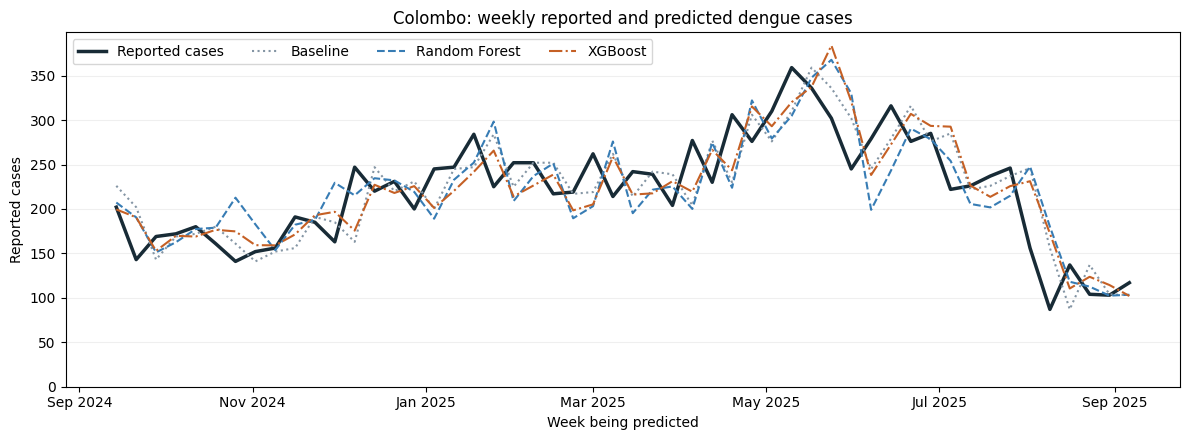

In [15]:
selected_district = "Colombo"  # Change to "Kandy" or another district to compare.

district_view = (
    comparison.loc[comparison["district"] == selected_district]
    .sort_values("week_start")
)

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(district_view["week_start"], district_view["actual_cases"],
        label="Reported cases", color="#182b36", linewidth=2.5)

for column, model, line_style in [
    ("baseline_prediction", "Baseline", ":"),
    ("rf_prediction", "Random Forest", "--"),
    ("xgb_prediction", "XGBoost", "-."),
]:
    ax.plot(district_view["week_start"], district_view[column],
            label=model, color=model_colors[model], linestyle=line_style)

ax.set_title(f"{selected_district}: weekly reported and predicted dengue cases")
ax.set_xlabel("Week being predicted")
ax.set_ylabel("Reported cases")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(ncol=4)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

### Random Forest and XGBoost performance by district

For each district, I subtract XGBoost's MAE from Random Forest's MAE.
A bar to the right of zero means XGBoost had lower error. A bar to the
left means Random Forest had lower error. A value close to zero means
the models performed similarly in that district.

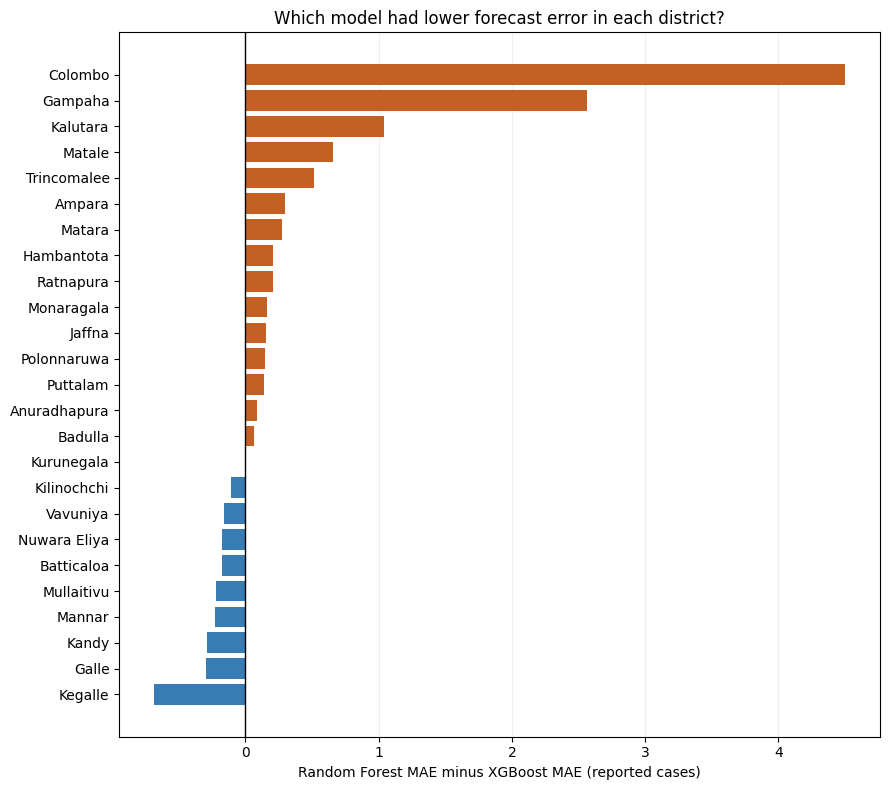

In [16]:
gain = (district_mae["Random Forest"] - district_mae["XGBoost"]).sort_values()

bar_colors = [
    model_colors["XGBoost"] if value >= 0 else model_colors["Random Forest"]
    for value in gain
]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(gain.index, gain, color=bar_colors)
ax.axvline(0, color="black", linewidth=1)

ax.set_title("Which model had lower forecast error in each district?")
ax.set_xlabel("Random Forest MAE minus XGBoost MAE (reported cases)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

## Stacking Random Forest and XGBoost

I will test whether a learned combination of the two forecasts improves
validation accuracy. I use two consecutive 52-week blocks from the end
of my training period to create practice predictions for the combiner.

For each block, I train fresh copies of Random Forest and XGBoost using
only weeks before that block. I then predict the block and keep both
predictions alongside the actual counts. This gives the combiner examples
of how the two models behave when forecasting unseen weeks.

In [17]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression

training_dates = pd.Index(train["week_start"].unique()).sort_values()
practice_blocks = [training_dates[-104:-52], training_dates[-52:]]
practice_results = []

for number, block_dates in enumerate(practice_blocks, start=1):
    earlier = train.loc[train["week_start"] < block_dates[0]]
    block = train.loc[train["week_start"].isin(block_dates)]

    # clone() copies the model settings and starts with an unfitted model.
    fold_rf = clone(rf_model)
    fold_xgb = clone(xgb_model)

    fold_rf.fit(earlier[features], earlier["actual_cases"])
    fold_xgb.fit(earlier[features], earlier["actual_cases"])

    block_results = block[["week_start", "district", "actual_cases"]].copy()
    block_results["rf_prediction"] = fold_rf.predict(block[features])
    block_results["xgb_prediction"] = fold_xgb.predict(block[features])
    practice_results.append(block_results)

    print(
        f"Block {number}: trained through {earlier['week_start'].max().date()}, "
        f"predicted {block_dates[0].date()} to {block_dates[-1].date()} "
        f"({len(block):,} district-week forecasts)"
    )

stack_train = pd.concat(practice_results, ignore_index=True)
print("Practice examples for the combiner:", len(stack_train))

Block 1: trained through 2022-09-10, predicted 2022-09-17 to 2023-09-09 (1,300 district-week forecasts)
Block 2: trained through 2023-09-09, predicted 2023-09-16 to 2024-09-07 (1,300 district-week forecasts)
Practice examples for the combiner: 2600


### Evaluate the stacked forecast

I fit a linear regression model that learns how to combine the RF and
XGBoost predictions. I then give it the validation predictions already
produced by the two models trained on the full training period.

All four methods are evaluated on the same district-week records. I keep
fractional forecasts when calculating error and set any negative stacked
case prediction to zero.

In [18]:
base_predictions = ["rf_prediction", "xgb_prediction"]

combiner = LinearRegression()
combiner.fit(stack_train[base_predictions], stack_train["actual_cases"])

stack_results = comparison.copy()
stack_results["stack_prediction"] = combiner.predict(
    stack_results[base_predictions]
).clip(min=0)

forecast_columns = {
    "baseline_prediction": "Baseline",
    "rf_prediction": "Random Forest",
    "xgb_prediction": "XGBoost",
    "stack_prediction": "Stacking",
}

forecasts = stack_results[list(forecast_columns)].rename(columns=forecast_columns)
assert forecasts.notna().all().all(), "Some forecasts are missing."

four_model_errors = forecasts.sub(stack_results["actual_cases"], axis=0).abs()
four_model_mae = four_model_errors.mean().sort_values()

print("Validation records compared:", len(forecasts))
display(four_model_mae.round(2).rename("Validation MAE").to_frame())

gain = four_model_mae["XGBoost"] - four_model_mae["Stacking"]
print(f"XGBoost MAE minus stacking MAE: {gain:+.3f} cases")

Validation records compared: 1300


,Validation MAE
XGBoost,8.14
Random Forest,8.49
Stacking,8.86
Baseline,9.00


XGBoost MAE minus stacking MAE: -0.720 cases


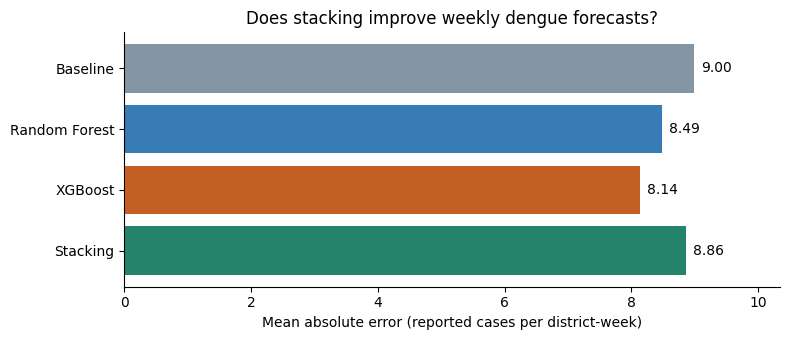

In [19]:
import matplotlib.pyplot as plt

plot_scores = four_model_mae.reindex(
    ["Baseline", "Random Forest", "XGBoost", "Stacking"]
)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(
    plot_scores.index,
    plot_scores.values,
    color=["#8495a4", "#377cb4", "#c56025", "#27846c"]
)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.invert_yaxis()
ax.set_xlim(0, plot_scores.max() * 1.15)
ax.set_xlabel("Mean absolute error (reported cases per district-week)")
ax.set_title("Does stacking improve weekly dengue forecasts?")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()